# Physics-Constrained Synthetic Solar PV Generation
## Notebook 3 of 3: usefulness, efficiency, figures, and your CV text

Needs in the Colab session: `solar_data.pkl` (Notebook 1) and `results_nb2.csv`, `cvae_models.pt` (Notebook 2).

1. Final results table
2. **TSTR**: is synthetic data actually *useful*? (train a forecaster on synthetic days, test on real days)
3. **Efficiency study**: how small can the decoder be before quality drops?
4. Does the model respond to the weather summary you ask for?
5. Auto-generated CV entry filled with your real numbers

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pickle, time, torch, torch.nn as nn
from scipy.stats import wasserstein_distance
from scipy.spatial.distance import cdist
from sklearn.neural_network import MLPRegressor

with open("solar_data.pkl","rb") as f: S = pickle.load(f)
TR, TE, CAP, RAMP_LIMIT, res_bs = S["TR"], S["TE"], S["CAP"], S["RAMP_LIMIT"], S["baseline"]
R = pd.read_csv("results_nb2.csv")
rng = np.random.default_rng(0)
dev = "cuda" if torch.cuda.is_available() else "cpu"

# ---- must match Notebook 2 exactly ----
LATENT, SIGMA, BETA, LAMBDA_RAMP = 8, 0.05, 1.0, 200.0
EPOCHS, BATCH, LR, SEEDS = 300, 128, 1e-3, [0,1,2]
VARIANTS = {"A: unconstrained": dict(use_env=False, use_ramp=False),
            "B: + envelope":    dict(use_env=True,  use_ramp=False),
            "C: + envelope + ramp": dict(use_env=True, use_ramp=True)}

def make_cond(D):
    ang = 2*np.pi*D["doy"]/365.25
    return np.stack([np.sin(ang), np.cos(ang), D["kt"]], 1).astype(np.float32)
def tens(D):
    return (torch.tensor(D["P"]/CAP, dtype=torch.float32), torch.tensor(make_cond(D)),
            torch.tensor(D["ENV"]/CAP, dtype=torch.float32))

class CVAE(nn.Module):
    def __init__(self, use_env, hid=128):
        super().__init__()
        self.use_env = use_env
        self.enc = nn.Sequential(nn.Linear(24+3+24, hid), nn.ReLU(), nn.Linear(hid, hid), nn.ReLU())
        self.mu, self.lv = nn.Linear(hid, LATENT), nn.Linear(hid, LATENT)
        self.dec = nn.Sequential(nn.Linear(LATENT+3+24, hid), nn.ReLU(), nn.Linear(hid, hid), nn.ReLU(), nn.Linear(hid, 24))
    def decode(self, z, c, env):
        out = self.dec(torch.cat([z, c, env], 1))
        return env * 1.1 * torch.sigmoid(out) if self.use_env else out
    def forward(self, x, c, env):
        h = self.enc(torch.cat([x, c, env], 1))
        mu, lv = self.mu(h), self.lv(h).clamp(-10, 6)
        z = mu + torch.randn_like(mu) * torch.exp(0.5*lv)
        return self.decode(z, c, env), mu, lv

def loss_fn(model, x, c, env, use_ramp, beta):
    xh, mu, lv = model(x, c, env)
    rec = ((xh - x)**2).sum(1) / (2*SIGMA**2)
    kl  = -0.5 * (1 + lv - mu**2 - lv.exp()).sum(1)
    loss = rec + beta*kl
    if use_ramp:
        r = (xh[:,1:] - xh[:,:-1]).abs()
        loss = loss + LAMBDA_RAMP * (torch.relu(r - RAMP_LIMIT)**2).sum(1)
    return loss.mean()

def train(use_env, use_ramp, seed, hid=128, epochs=EPOCHS):
    torch.manual_seed(seed); np.random.seed(seed)
    model = CVAE(use_env, hid).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    x, c, env = [t.to(dev) for t in tens(TR)]
    n = len(x)
    for ep in range(epochs):
        beta = BETA * min(1.0, (ep+1)/(0.3*epochs))
        perm = torch.randperm(n, device=dev)
        for i in range(0, n, BATCH):
            b = perm[i:i+BATCH]
            loss = loss_fn(model, x[b], c[b], env[b], use_ramp, beta)
            opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

@torch.no_grad()
def sample(model, D, n_per=1, seed=0):
    g = torch.Generator(device="cpu").manual_seed(seed)
    _, c, env = tens(D)
    c, env = c.repeat(n_per,1).to(dev), env.repeat(n_per,1).to(dev)
    z = torch.randn(len(c), LATENT, generator=g).to(dev)
    return model.decode(z, c, env).cpu().numpy()*CAP, env.cpu().numpy()*CAP

def violation_mask(P, ENV, margin=1.10, night_tol=1.0):
    v_night = ((P > night_tol) & (ENV < night_tol)).any(1)
    v_neg   = (P < -1e-6).any(1)
    v_env   = (P > ENV*margin + night_tol).any(1)
    v_ramp  = (np.abs(np.diff(P,axis=1))/CAP > RAMP_LIMIT).any(1)
    return v_night | v_neg | v_env | v_ramp

def evaluate(P_syn, ENV_syn, P_real=TE["P"], P_train=TR["P"], n_nn=1500):
    kw = lambda x: x/1000.0
    sub = rng.choice(len(P_syn), size=min(n_nn, len(P_syn)), replace=False)
    return dict(wd_value=wasserstein_distance(kw(P_syn).ravel(), kw(P_real).ravel()),
                wd_ramp=wasserstein_distance(kw(np.diff(P_syn,axis=1)).ravel(), kw(np.diff(P_real,axis=1)).ravel()),
                profile_rmse=float(np.sqrt(np.mean((kw(P_syn).mean(0)-kw(P_real).mean(0))**2))),
                violation_rate=float(violation_mask(P_syn, ENV_syn).mean()),
                novelty=float(cdist(kw(P_syn[sub]), kw(P_train)).min(1).mean()))

models = {}
ck = torch.load("cvae_models.pt", map_location=dev)
for v, kw_ in VARIANTS.items():
    for s in SEEDS:
        m = CVAE(kw_["use_env"]).to(dev); m.load_state_dict(ck[f"{v}|{s}"]); models[(v,s)] = m.eval()
print("loaded", len(models), "models")

loaded 9 models


## 1. Fidelity and physics: mean ± std over 3 seeds

In [ ]:
metrics = ["wd_value","wd_ramp","profile_rmse","hard_violation_rate","novelty"]
g = R.groupby("variant")[metrics].agg(["mean","std"])
table = pd.DataFrame({m: [f"{g[(m,'mean')][v]:.4f} ± {g[(m,'std')][v]:.4f}" for v in VARIANTS] for m in metrics}, index=list(VARIANTS))
table.loc["Seasonal bootstrap"] = [f"{res_bs[m]:.4f}" for m in metrics]
table

,wd_value,wd_ramp,profile_rmse,hard_violation_rate,novelty
A: unconstrained,0.0035 ± 0.0006,0.0055 ± 0.0006,0.0052 ± 0.0010,1.0000 ± 0.0000,0.0859 ± 0.0002
B: + envelope,0.0022 ± 0.0002,0.0043 ± 0.0002,0.0041 ± 0.0013,0.0000 ± 0.0000,0.0799 ± 0.0008
C: + envelope + ramp,0.0023 ± 0.0002,0.0042 ± 0.0002,0.0041 ± 0.0009,0.0000 ± 0.0000,0.0797 ± 0.0012
Seasonal bootstrap,0.0045,0.0016,0.0081,0.0575,0.0000


## 2. TSTR: Train on Synthetic, Test on Real
**Task:** given the morning (hours 0 to 11), the day of year and the afternoon's clear-sky envelope, forecast the afternoon (hours 12 to 23).

A forecaster is trained on (a) real days, (b) bootstrap days, (c) synthetic days from each variant, then **always tested on real, unseen test days**. If synthetic data is good, the score lands close to the real-data score. A naive baseline (scale the clear-sky envelope by how sunny the morning was) is included so the numbers have meaning.

In [ ]:
def feats(P, ENV, doy):
    ang = 2*np.pi*doy/365.25
    return np.hstack([P[:, :12]/CAP, ENV[:, 12:]/CAP, np.sin(ang)[:,None], np.cos(ang)[:,None]])
def targ(P): return P[:, 12:]/CAP

def fit_eval(P_tr, ENV_tr, doy_tr, seed=0):
    f = MLPRegressor((64,64), max_iter=300, early_stopping=True, random_state=seed)
    f.fit(feats(P_tr, ENV_tr, doy_tr), targ(P_tr))
    pred = np.clip(f.predict(feats(TE["P"], TE["ENV"], TE["doy"])), 0, None)
    return float(np.sqrt(np.mean((pred - targ(TE["P"]))**2)) * CAP)      # RMSE in W per kWp

# naive benchmark: clear-sky persistence
k = TE["P"][:, :12].sum(1) / np.clip(TE["ENV"][:, :12].sum(1), 1, None)
naive = float(np.sqrt(np.mean((np.clip(k[:,None]*TE["ENV"][:, 12:], 0, None) - TE["P"][:, 12:])**2)))

tstr = {"Naive clear-sky persistence": [naive],
        "Trained on REAL days": [fit_eval(TR["P"], TR["ENV"], TR["doy"], s) for s in SEEDS]}
# bootstrap synthetic
def seasonal_bootstrap(doy_target, window=15):
    idx = []
    for d in doy_target:
        dist = np.abs(((TR["doy"] - d + 183) % 366) - 183)
        idx.append(rng.choice(np.where(dist <= window)[0]))
    return np.array(idx)
bi = seasonal_bootstrap(TR["doy"])
tstr["Trained on bootstrap days"] = [fit_eval(TR["P"][bi], TR["ENV"][bi], TR["doy"], s) for s in SEEDS]
for v in VARIANTS:
    out = []
    for s in SEEDS:
        P_s, E_s = sample(models[(v,s)], TR, seed=s)
        out.append(fit_eval(P_s, E_s, TR["doy"], s))
    tstr[f"Trained on {v}"] = out
tstr_df = pd.DataFrame({k: [np.mean(v), np.std(v) if len(v)>1 else np.nan] for k, v in tstr.items()}, index=["RMSE mean (W/kWp)","std"]).T.round(2)
tstr_df

,RMSE mean (W/kWp),std
Naive clear-sky persistence,80.92,NaN
Trained on REAL days,72.77,0.07
Trained on bootstrap days,73.48,0.22
Trained on A: unconstrained,75.26,0.56
Trained on B: + envelope,74.40,0.11
Trained on C: + envelope + ramp,74.31,0.21


## 3. Efficiency study: how small can the decoder be?
Variant C is retrained with decoder widths from tiny to large (1 seed each, to keep runtime reasonable; widen `SEEDS_EFF` if you want error bars). Parameters count the decoder only, since that is all you need to generate data.

In [ ]:
SEEDS_EFF, WIDTHS = [0,1,2], [8, 16, 32, 64, 128, 256]
rows = []
for w in WIDTHS:
    for s in SEEDS_EFF:
        m = train(True, True, s, hid=w)
        P_s, E_s = sample(m, TE, seed=s)
        r = evaluate(P_s, E_s)
        mc = CVAE(True, w); mc.load_state_dict({k: v.cpu() for k, v in m.state_dict().items()}); mc.eval()
        c = torch.randn(1000,3); env = torch.rand(1000,24); z = torch.randn(1000, LATENT)
        with torch.no_grad():
            mc.decode(z, c, env); t0 = time.perf_counter()
            for _ in range(20): mc.decode(z, c, env)
        r.update(width=w, decoder_params=sum(p.numel() for p in mc.dec.parameters()),
                 cpu_ms_per_1000_days=(time.perf_counter()-t0)/20*1000)
        rows.append(r); print("width", w, "done")
EFF = pd.DataFrame(rows).groupby("width").mean().round(4)
EFF[["decoder_params","cpu_ms_per_1000_days","wd_value","wd_ramp","violation_rate","novelty"]]

width 8 done
width 8 done
width 8 done
width 16 done
width 16 done
width 16 done
width 32 done
width 32 done
width 32 done
width 64 done
width 64 done
width 64 done
width 128 done
width 128 done
width 128 done
width 256 done
width 256 done
width 256 done


,decoder_params,cpu_ms_per_1000_days,wd_value,wd_ramp,violation_rate,novelty
width,,,,,,
8,576.0,0.3108,0.0060,0.0088,0.0,0.0855
16,1256.0,0.3913,0.0044,0.0074,0.0,0.0798
32,3000.0,0.3605,0.0041,0.0070,0.0,0.0790
64,8024.0,0.5655,0.0033,0.0056,0.0,0.0811
128,24216.0,1.1851,0.0023,0.0042,0.0,0.0797
256,81176.0,2.4807,0.0022,0.0040,0.0,0.0811


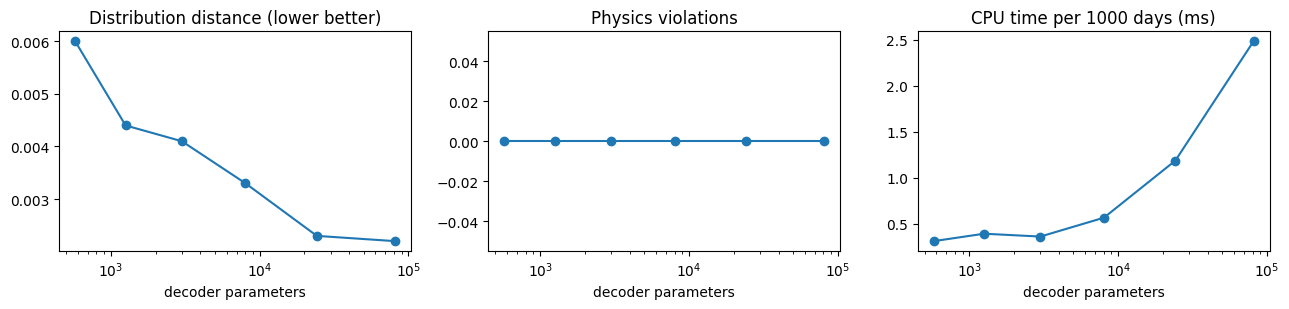

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, m_, t in zip(ax, ["wd_value","violation_rate","cpu_ms_per_1000_days"], ["Distribution distance (lower better)","Physics violations","CPU time per 1000 days (ms)"]):
    a.plot(EFF["decoder_params"], EFF[m_], "o-"); a.set_xscale("log"); a.set_xlabel("decoder parameters"); a.set_title(t)
plt.tight_layout(); plt.show()

In [ ]:
def vr(P, E):   # hard physics only
    bad = ((P > 1) & (E < 1)).any(1) | (P < -1e-6).any(1) | (P > E*1.1 + 1).any(1)
    return float(bad.mean())
def day_mask(E): return (E[:, 1:] > 50) & (E[:, :-1] > 50)
def rr(P, E):   # share of daytime hour-pairs above RAMP_LIMIT
    return float((np.abs(np.diff(P, axis=1))/CAP > RAMP_LIMIT)[day_mask(E)].mean())
def tails(P, E):
    r = (np.abs(np.diff(P, axis=1))/CAP)[day_mask(E)]
    return np.quantile(r, [0.5, 0.9, 0.99, 0.999]).round(3)
def row(name, P, E):
    r = evaluate(P, E)
    return dict(name=name, wd_value=r["wd_value"], wd_ramp=r["wd_ramp"], novelty=r["novelty"],
                hard_viol=vr(P, E), ramp_exceed=rr(P, E), tail_q50_90_99_999=tails(P, E))

n = len(TE["P"])
rows = [row("REAL test (reference)", TE["P"], TE["ENV"]),
        row("REAL train tail (noise floor)", TR["P"][-n:], TR["ENV"][-n:])]
for v in VARIANTS:
    P, E = sample(models[(v, 0)], TE, seed=0)
    rows.append(row(v, P, E))
    if v.startswith("A"): rows.append(row("A + post-hoc clip", np.clip(P, 0, E*1.1), E))
display(pd.DataFrame(rows).set_index("name").round(4))

knee = EFF[EFF["wd_value"] <= 1.25*EFF["wd_value"].iloc[-1]].index.min()
print("efficiency knee width:", knee); display(EFF[["decoder_params","wd_value","cpu_ms_per_1000_days"]])

,wd_value,wd_ramp,novelty,hard_viol,ramp_exceed,tail_q50_90_99_999
name,,,,,,
REAL test (reference),0.0000,0.0000,0.0922,0.0082,0.0004,"[0.116, 0.217, 0.412, 0.608]"
REAL train tail (noise floor),0.0015,0.0007,0.0000,0.0150,0.0001,"[0.117, 0.219, 0.421, 0.638]"
A: unconstrained,0.0041,0.0059,0.0860,1.0000,0.0000,"[0.119, 0.195, 0.312, 0.457]"
A + post-hoc clip,0.0036,0.0055,0.0849,0.0041,0.0000,"[0.119, 0.195, 0.307, 0.444]"
B: + envelope,0.0024,0.0044,0.0794,0.0000,0.0000,"[0.12, 0.197, 0.306, 0.473]"
C: + envelope + ramp,0.0025,0.0043,0.0786,0.0000,0.0000,"[0.118, 0.197, 0.295, 0.483]"


efficiency knee width: 128


,decoder_params,wd_value,cpu_ms_per_1000_days
width,,,
8,576.0,0.0060,0.3108
16,1256.0,0.0044,0.3913
32,3000.0,0.0041,0.3605
64,8024.0,0.0033,0.5655
128,24216.0,0.0023,1.1851
256,81176.0,0.0022,2.4807


In [ ]:
rows = []
for s in SEEDS:
    for name, v in [("A + clip","A: unconstrained"), ("B","B: + envelope"), ("C","C: + envelope + ramp")]:
        P, E = sample(models[(v, s)], TE, seed=s)
        if name == "A + clip": P = np.clip(P, 0, E*1.1)
        r = evaluate(P, E)
        rows.append(dict(model=name, seed=s, wd_value=r["wd_value"], wd_ramp=r["wd_ramp"], q99=tails(P, E)[2]))
d = pd.DataFrame(rows)
display(d.groupby("model")[["wd_value","wd_ramp","q99"]].agg(["mean","std"]).round(4))
display(d.pivot(index="seed", columns="model", values="wd_value").round(4))

wd_value         wd_ramp             q99        
             mean     std    mean     std    mean     std
model                                                    
A + clip   0.0030  0.0006  0.0050  0.0006  0.2943  0.0112
B          0.0022  0.0002  0.0043  0.0002  0.3097  0.0064
C          0.0023  0.0002  0.0042  0.0002  0.3040  0.0085

model,A + clip,B,C
seed,,,
0,0.0036,0.0024,0.0025
1,0.0031,0.0023,0.0022
2,0.0024,0.0020,0.0022


In [ ]:
for sg in [0.05, 0.03, 0.02]:
    SIGMA = sg
    m = train(True, False, seed=0); P, E = sample(m, TE, seed=0); r = evaluate(P, E)
    print(sg, round(r["wd_value"],4), round(r["wd_ramp"],4), round(r["novelty"],4), tails(P, E))
SIGMA = 0.05

0.05 0.0024 0.0044 0.0794 [0.12  0.197 0.306 0.473]
0.03 0.0035 0.0044 0.0886 [0.119 0.2   0.296 0.431]
0.02 0.0039 0.0032 0.1025 [0.119 0.21  0.324 0.444]


## 4. Does the model obey the weather you ask for?
We request days at a grid of clearness indices and check that the generated days actually have that clearness index. A good conditional model tracks the diagonal.

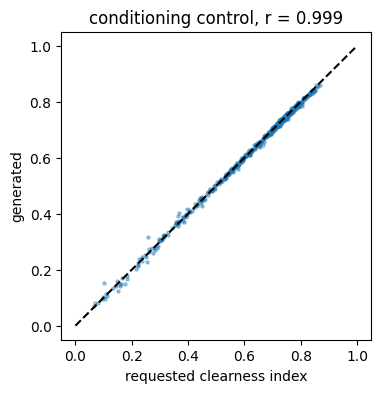

In [ ]:
best_v = "C: + envelope + ramp"
m = models[(best_v, 0)]

# Select up to 800 unique test samples
n = min(800, len(TE["P"]))
sel = rng.choice(len(TE["P"]), n, replace=False)

sub = {k: v[sel] for k, v in TE.items()}

P_s, E_s = sample(m, sub, seed=3)

kt_gen = P_s.sum(1) / np.clip(E_s.sum(1), 1, None)
corr = np.corrcoef(sub["kt"], kt_gen)[0, 1]

plt.figure(figsize=(4, 4))
plt.scatter(sub["kt"], kt_gen, s=5, alpha=.4)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("requested clearness index")
plt.ylabel("generated")
plt.title(f"conditioning control, r = {corr:.3f}")
plt.show()

## 5. Your CV entry, filled with the numbers you just produced

In [ ]:
metrics = ["wd_value", "wd_ramp", "profile_rmse", "hard_violation_rate", "novelty"]

A, B, Cv = "A: unconstrained", "B: + envelope", "C: + envelope + ramp"

gm = R.groupby("variant")[metrics].mean()

viol_A = gm.loc[A, "hard_violation_rate"] * 100
viol_C = gm.loc[Cv, "hard_violation_rate"] * 100

real_rmse = np.mean(tstr["Trained on REAL days"])
c_rmse = np.mean(tstr[f"Trained on {Cv}"])

small = EFF.iloc[0]
big = EFF.iloc[-1]

print(f"""Physics-Constrained Synthetic Solar PV Generation (Python, PyTorch, pvlib)
- Built conditional VAEs generating daily hourly PV profiles from {len(TR["P"])} days of real PVGIS data, conditioned on day-of-year and clearness index; hard-coded a pvlib clear-sky envelope into the decoder (zero output at night, no output above the physical limit).
- Ablation of 3 identical-architecture variants (unconstrained / +envelope / +envelope+ramp-rate penalty), 3 seeds each: physical-violation rate fell from {viol_A:.1f}% to {viol_C:.1f}%, versus {res_bs["hard_violation_rate"]*100:.1f}% for a seasonal-bootstrap baseline that cannot generate new days (novelty {res_bs["novelty"]:.3f} vs {gm.loc[Cv,"novelty"]:.3f}).
- Downstream utility (train-on-synthetic, test-on-real, afternoon forecasting): RMSE {c_rmse:.1f} W/kWp vs {real_rmse:.1f} for real-data training and {tstr["Naive clear-sky persistence"][0]:.1f} for a naive baseline.
- Efficiency: decoder of {int(small.decoder_params)} parameters ({small.cpu_ms_per_1000_days:.2f} ms per 1000 days on CPU) vs {int(big.decoder_params)} parameters ({big.cpu_ms_per_1000_days:.2f} ms), with Wasserstein distance {small.wd_value:.4f} vs {big.wd_value:.4f}.""")

print("\nCheck every sentence against the tables above before using it. If a claim is not supported (for example C is not better than A), edit the sentence to say what actually happened.")

Physics-Constrained Synthetic Solar PV Generation (Python, PyTorch, pvlib)
- Built conditional VAEs generating daily hourly PV profiles from 5113 days of real PVGIS data, conditioned on day-of-year and clearness index; hard-coded a pvlib clear-sky envelope into the decoder (zero output at night, no output above the physical limit).
- Ablation of 3 identical-architecture variants (unconstrained / +envelope / +envelope+ramp-rate penalty), 3 seeds each: physical-violation rate fell from 100.0% to 0.0%, versus 5.7% for a seasonal-bootstrap baseline that cannot generate new days (novelty 0.000 vs 0.080).
- Downstream utility (train-on-synthetic, test-on-real, afternoon forecasting): RMSE 74.3 W/kWp vs 72.8 for real-data training and 80.9 for a naive baseline.
- Efficiency: decoder of 576 parameters (0.31 ms per 1000 days on CPU) vs 81176 parameters (2.48 ms), with Wasserstein distance 0.0060 vs 0.0022.

Check every sentence against the tables above before using it. If a claim is not support